# EN4554 Assignment 2: Convolutional Neural Networks

**Name:** Induwara Ilukkumbura  
**Index number:** 220235V  
**Course:** EN4554 — Deep Learning for Vision
https://github.com/induwara-iluk/EN4554_CNN_assignment/blob/main/220235V_CNN_Assignment.ipynb

This notebook covers Tasks 1–3 of the assignment. Task 4 is optional and is not included here. The code and results are kept together so the notebook can be exported as a PDF report.

In [48]:
import os, time, math, copy, random, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import pandas as pd

QUICK = False          # True -> tiny subset + few epochs, just to check that everything runs

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
print('device:', device, '| torch', torch.__version__, '| AMP:', USE_AMP)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

def seed_all(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all(0)
torch.backends.cudnn.benchmark = True

# ---- experiment sizes (full vs quick) --------------------------------------
CFG = dict(
    n_train   = 45_000 if not QUICK else 2_000,
    n_val     = 5_000  if not QUICK else 1_000,
    ep_t1     = 10 if not QUICK else 1,     # Task 1c MLP epochs
    ep_t2     = 8  if not QUICK else 1,     # Task 2c epochs per (optimizer, lr)
    ep_t3a    = 30 if not QUICK else 1,     # Task 3a epochs (5k subset)
    n_t3a     = 5_000 if not QUICK else 1_000,
    ep_t3b    = 20 if not QUICK else 1,     # Task 3b epochs per network
    depths_3b = [8, 20, 56] if not QUICK else [8, 20],
    ep_t4     = 20 if not QUICK else 1,     # Task 4 (hard limit 20)
    bs        = 128,
)
print(json.dumps(CFG, indent=1))

device: cuda | torch 2.11.0+cu130 | AMP: True
Tesla T4
{
 "n_train": 45000,
 "n_val": 5000,
 "ep_t1": 10,
 "ep_t2": 8,
 "ep_t3a": 30,
 "n_t3a": 5000,
 "ep_t3b": 20,
 "depths_3b": [
  8,
  20,
  56
 ],
 "ep_t4": 20,
 "bs": 128
}


## Dataset and setup

CIFAR-10 contains 60,000 colour images of size 32 × 32 pixels across ten classes. The official training set has 50,000 images and the test set has 10,000 images. Here, the training set is split into 45,000 training images and 5,000 validation images using a fixed random seed. Channel normalization statistics are calculated from the training split only.

The test set is not loaded or used in Tasks 1–3.

train (45000, 3, 32, 32) val (5000, 3, 32, 32)
channel mean [0.4912 0.482  0.4464] std [0.2472 0.2436 0.2617]


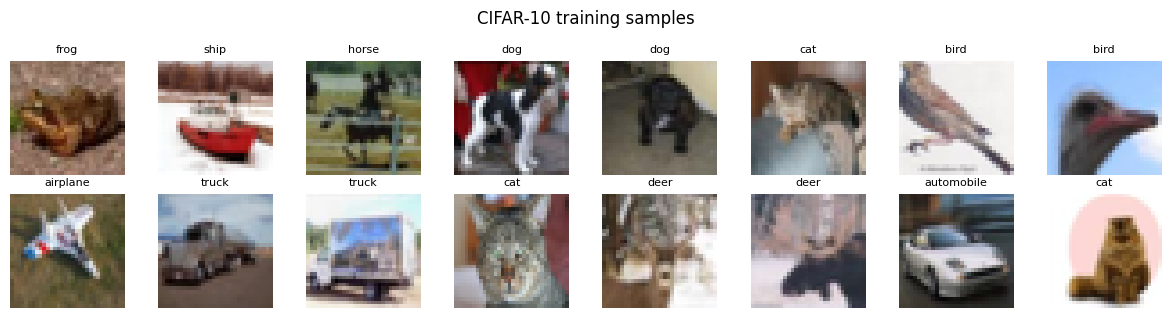

In [49]:
root = './data'
full_train = torchvision.datasets.CIFAR10(root, train=True, download=True)
X_all = torch.from_numpy(np.asarray(full_train.data)).permute(0, 3, 1, 2).contiguous()   # (50000,3,32,32) uint8
y_all = torch.tensor(full_train.targets, dtype=torch.long)
CLASSES = full_train.classes

# fixed, seeded 45k / 5k split
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(X_all), generator=g)
tr_idx, va_idx = perm[:45_000], perm[45_000:50_000]
tr_idx, va_idx = tr_idx[:CFG['n_train']], va_idx[:CFG['n_val']]

X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]

# per-channel mean / std from the TRAINING split only
MEAN = X_tr.float().div(255).mean(dim=(0, 2, 3))
STD  = X_tr.float().div(255).std(dim=(0, 2, 3))
print('train', tuple(X_tr.shape), 'val', tuple(X_va.shape))
print('channel mean', MEAN.numpy().round(4), 'std', STD.numpy().round(4))

X_tr, y_tr, X_va, y_va = X_tr.to(device), y_tr.to(device), X_va.to(device), y_va.to(device)
MEAN_D, STD_D = MEAN.to(device).view(1, 3, 1, 1), STD.to(device).view(1, 3, 1, 1)

def normalize(x_uint8):
    return (x_uint8.float().div_(255) - MEAN_D) / STD_D

class GPULoader:
    '''Iterates over (x, y) mini-batches that already live on the GPU.
    aug: optional function applied to the normalised float batch.'''
    def __init__(self, X, y, bs, shuffle=True, aug=None, drop_last=False):
        self.X, self.y, self.bs, self.shuffle, self.aug, self.drop_last = X, y, bs, shuffle, aug, drop_last
    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)
    def __iter__(self):
        n = len(self.X)
        idx = torch.randperm(n, device=self.X.device) if self.shuffle else torch.arange(n, device=self.X.device)
        for i in range(0, n - (n % self.bs if self.drop_last else 0), self.bs):
            b = idx[i:i + self.bs]
            x = normalize(self.X[b])
            if self.aug is not None:
                x = self.aug(x)
            yield x, self.y[b]

# a quick look at the data
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_tr[i].permute(1, 2, 0).cpu().numpy()); ax.set_title(CLASSES[y_tr[i]], fontsize=8); ax.axis('off')
plt.suptitle('CIFAR-10 training samples'); plt.tight_layout(); plt.show()

## Task 1 — Backpropagation

### 1(a) Manual forward and backward operations



In [75]:
class Linear:
    def __init__(self, in_features, out_features):
        self.W = torch.randn(in_features, out_features, device=device) * (2 / in_features) ** 0.5
        self.b = torch.zeros(out_features, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, grad):
        self.dW = self.x.T @ grad
        self.db = grad.sum(dim=0)
        return grad @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x.clamp(min=0)

    def backward(self, grad):
        return grad * self.mask


def softmax_cross_entropy(logits, targets):
    # Numerically stable softmax
    shifted = logits - logits.max(dim=1, keepdim=True).values
    exp_scores = shifted.exp()
    probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)

    n = logits.shape[0]
    loss = -torch.log(
        probs[torch.arange(n, device=device), targets] + 1e-12
    ).mean()

    grad = probs.clone()
    grad[torch.arange(n, device=device), targets] -= 1
    grad /= n

    return loss, grad

In [76]:
class MLP:
    def __init__(self, input_size=3072, hidden_size=256, num_classes=10):
        self.fc1 = Linear(input_size, hidden_size)
        self.relu = ReLU()
        self.fc2 = Linear(hidden_size, num_classes)

    def forward(self, x):
        x = x.flatten(start_dim=1)
        x = self.fc1.forward(x)
        x = self.relu.forward(x)
        return self.fc2.forward(x)

    def backward(self, grad):
        grad = self.fc2.backward(grad)
        grad = self.relu.backward(grad)
        self.fc1.backward(grad)

    def parameters(self):
        return [
            (self.fc1.W, self.fc1.dW),
            (self.fc1.b, self.fc1.db),
            (self.fc2.W, self.fc2.dW),
            (self.fc2.b, self.fc2.db),
        ]

The next cell checks that the forward pass produces ten class scores per image and that the backward pass produces a weight gradient of the expected shape.

In [77]:
model = MLP()

x, y = next(iter(GPULoader(X_tr, y_tr, bs=64, shuffle=True)))

logits = model.forward(x)
loss, grad = softmax_cross_entropy(logits, y)
model.backward(grad)

print("Logits shape:", logits.shape)
print("Loss:", loss.item())
print("Weight gradient shape:", model.fc1.dW.shape)

Logits shape: torch.Size([64, 10])
Loss: 3.1310291290283203
Weight gradient shape: torch.Size([3072, 256])


### 1(b) Gradient verification against autograd

The manual gradients are compared with PyTorch autograd on a small batch. Relative error measures the difference between the two results, and `torch.allclose` checks whether they agree within a tolerance.

In [78]:
import torch.nn.functional as F

# Use a small batch for verification
x_test, y_test = x[:8], y[:8]

# 1. Manual gradients
logits = model.forward(x_test)
loss_manual, grad = softmax_cross_entropy(logits, y_test)
model.backward(grad)

manual_grads = [
    model.fc1.dW.clone(), model.fc1.db.clone(),
    model.fc2.dW.clone(), model.fc2.db.clone()
]

# 2. Autograd reference
W1 = model.fc1.W.detach().clone().requires_grad_(True)
b1 = model.fc1.b.detach().clone().requires_grad_(True)
W2 = model.fc2.W.detach().clone().requires_grad_(True)
b2 = model.fc2.b.detach().clone().requires_grad_(True)

z1 = x_test.flatten(1) @ W1 + b1
h1 = z1.relu()
logits_ref = h1 @ W2 + b2
loss_ref = F.cross_entropy(logits_ref, y_test)
loss_ref.backward()

auto_grads = [W1.grad, b1.grad, W2.grad, b2.grad]

# Relative errors and allclose checks
for name, gm, ga in zip(
    ["W1", "b1", "W2", "b2"], manual_grads, auto_grads
):
    rel_error = (gm - ga).norm() / (ga.norm() + 1e-12)
    print(name, "relative error:", rel_error.item(),
          "| allclose:", torch.allclose(gm, ga, rtol=1e-4, atol=1e-6))

W1 relative error: 5.25043155619187e-08 | allclose: True
b1 relative error: 5.416027804017176e-08 | allclose: True
W2 relative error: 3.118242730693055e-08 | allclose: True
b2 relative error: 4.6087947680462094e-08 | allclose: True


Centred finite differences provide an independent numerical check for a few representative parameters. Only a few entries are checked because finite-difference calculations are expensive for large weight matrices.

In [79]:
def loss_at(W1, b1, W2, b2):
    logits = (x_test.flatten(1) @ W1 + b1).relu() @ W2 + b2
    return F.cross_entropy(logits, y_test)

eps = 1e-3

checks = [
    (model.fc1.W, model.fc1.dW, (0, 0)),
    (model.fc1.b, model.fc1.db, (0,)),
    (model.fc2.W, model.fc2.dW, (0, 0)),
    (model.fc2.b, model.fc2.db, (0,))
]

for i, (param, grad_manual, idx) in enumerate(checks):
    original = param[idx].item()

    with torch.no_grad():
        param[idx] = original + eps
    plus = loss_at(model.fc1.W, model.fc1.b,
                   model.fc2.W, model.fc2.b).item()

    with torch.no_grad():
        param[idx] = original - eps
    minus = loss_at(model.fc1.W, model.fc1.b,
                    model.fc2.W, model.fc2.b).item()

    with torch.no_grad():
        param[idx] = original

    numerical = (plus - minus) / (2 * eps)
    analytical = grad_manual[idx].item()
    rel_error = abs(numerical - analytical) / (
        abs(numerical) + abs(analytical) + 1e-12
    )

    print(f"Parameter {i}: manual={analytical:.6g}, "
          f"finite difference={numerical:.6g}, "
          f"relative error={rel_error:.3e}")

Parameter 0: manual=-0.000833878, finite difference=-0.000953674, relative error=6.702e-02
Parameter 1: manual=-0.00868414, finite difference=-0.00858307, relative error=5.853e-03
Parameter 2: manual=0.0652427, finite difference=0.0652075, relative error=2.698e-04
Parameter 3: manual=0.137881, finite difference=0.137806, relative error=2.718e-04


### 1(c) Train the MLP

The images are flattened into 3,072-element vectors and the MLP is trained using SGD. Training and validation loss and accuracy are recorded after each epoch. A gap between training and validation performance indicates how well the model generalizes.

In [80]:
EPOCHS = 50
BATCH_SIZE = 256
LR = 0.01
# Start a completely fresh experiment
torch.manual_seed(42)
model = MLP()

# Reset experiment history too
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}

for epoch in range(EPOCHS):
    total_loss, correct, total = 0.0, 0, 0

    for xb, yb in GPULoader(X_tr, y_tr, BATCH_SIZE, shuffle=True):
        logits = model.forward(xb)
        loss, grad = softmax_cross_entropy(logits, yb)
        model.backward(grad)

        with torch.no_grad():
            for param, g in model.parameters():
                param -= LR * g

        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(yb)

    history["train_loss"].append(total_loss / total)
    history["train_acc"].append(100 * correct / total)

    # Validation: no weight updates
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for xb, yb in GPULoader(X_va, y_va, BATCH_SIZE, shuffle=False):
            logits = model.forward(xb)
            loss, _ = softmax_cross_entropy(logits, yb)

            val_loss_sum += loss.item() * len(yb)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += len(yb)

    history["val_loss"].append(val_loss_sum / val_total)
    history["val_acc"].append(100 * val_correct / val_total)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train loss: {history['train_loss'][-1]:.4f} | "
        f"Val loss: {history['val_loss'][-1]:.4f} | "
        f"Train acc: {history['train_acc'][-1]:.2f}% | "
        f"Val acc: {history['val_acc'][-1]:.2f}%"
    )

Epoch 01/50 | Train loss: 1.9151 | Val loss: 1.7731 | Train acc: 33.22% | Val acc: 37.82%
Epoch 02/50 | Train loss: 1.6675 | Val loss: 1.6952 | Train acc: 41.66% | Val acc: 40.16%
Epoch 03/50 | Train loss: 1.5819 | Val loss: 1.6459 | Train acc: 44.81% | Val acc: 42.50%
Epoch 04/50 | Train loss: 1.5256 | Val loss: 1.6093 | Train acc: 46.99% | Val acc: 43.22%
Epoch 05/50 | Train loss: 1.4831 | Val loss: 1.5897 | Train acc: 48.40% | Val acc: 44.22%
Epoch 06/50 | Train loss: 1.4465 | Val loss: 1.5682 | Train acc: 50.02% | Val acc: 45.10%
Epoch 07/50 | Train loss: 1.4158 | Val loss: 1.5563 | Train acc: 51.28% | Val acc: 45.44%
Epoch 08/50 | Train loss: 1.3875 | Val loss: 1.5417 | Train acc: 52.20% | Val acc: 46.34%
Epoch 09/50 | Train loss: 1.3634 | Val loss: 1.5284 | Train acc: 53.05% | Val acc: 46.46%
Epoch 10/50 | Train loss: 1.3400 | Val loss: 1.5164 | Train acc: 53.96% | Val acc: 47.78%
Epoch 11/50 | Train loss: 1.3193 | Val loss: 1.5078 | Train acc: 54.84% | Val acc: 47.90%
Epoch 12/5

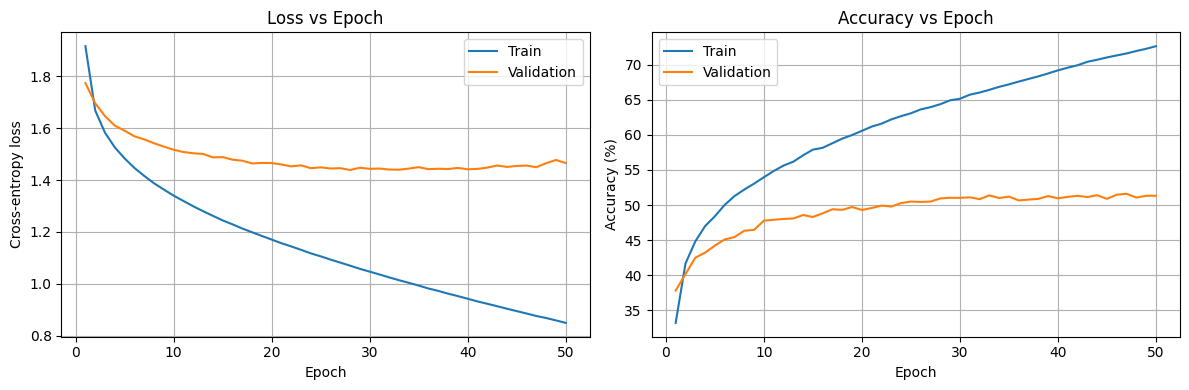

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, EPOCHS + 1)

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set_title("Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_acc"], label="Train")
axes[1].plot(epochs, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Task 1(c) interpretation.** The training loss decreases throughout training, and training accuracy improves. Validation accuracy remains much lower and changes only modestly, while validation loss stops improving consistently. This indicates a generalization gap: the MLP learns the training data better than it learns to classify unseen images. Flattening the image also removes the spatial structure.

In [82]:
correct, total = 0, 0

with torch.no_grad():
    for xb, yb in GPULoader(X_va, y_va, BATCH_SIZE, shuffle=False):
        logits = model.forward(xb)
        predictions = logits.argmax(dim=1)
        correct += (predictions == yb).sum().item()
        total += len(yb)

val_accuracy = 100 * correct / total
print(f"Validation accuracy: {val_accuracy:.2f}%")

Validation accuracy: 51.32%


### 1(d) Gradient flow in a 10-layer MLP

The gradient norms are measured at initialization for networks using sigmoid and ReLU activations. The same initial weights are used for both runs to make the comparison more controlled.

In [83]:
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)

# 10 linear layers: input -> 9 hidden layers -> 10 classes
sizes = [3072] + [128] * 9 + [10]

# Shared Xavier initialization for a controlled comparison
initial_weights, initial_biases = [], []

for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
    w = torch.empty(fan_in, fan_out, device=device)
    nn.init.xavier_uniform_(w)
    initial_weights.append(w)
    initial_biases.append(torch.zeros(fan_out, device=device))


def gradient_norms(activation):
    weights = [
        w.detach().clone().requires_grad_(True)
        for w in initial_weights
    ]
    biases = [
        b.detach().clone().requires_grad_(True)
        for b in initial_biases
    ]

    x, y = next(iter(GPULoader(X_tr, y_tr, bs=128, shuffle=False)))
    x = x.flatten(1)

    for i, (w, b) in enumerate(zip(weights, biases)):
        x = x @ w + b
        if i < len(weights) - 1:
            x = activation(x)

    loss = F.cross_entropy(x, y)
    loss.backward()

    return [w.grad.norm().item() for w in weights]


sigmoid_norms = gradient_norms(torch.sigmoid)
relu_norms = gradient_norms(F.relu)

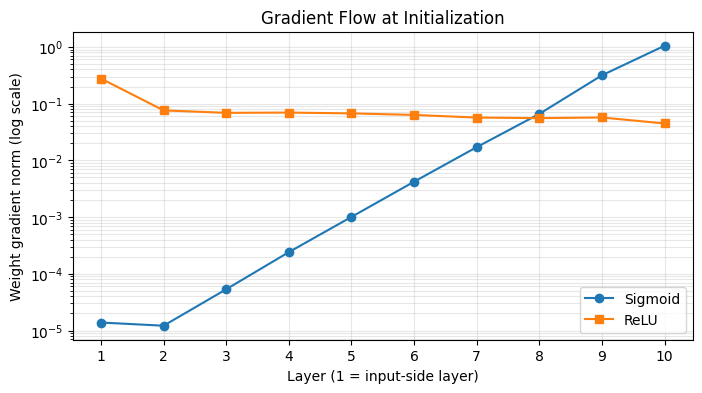

In [84]:
layers = range(1, 11)

plt.figure(figsize=(8, 4))
plt.semilogy(layers, sigmoid_norms, marker='o', label='Sigmoid')
plt.semilogy(layers, relu_norms, marker='s', label='ReLU')
plt.xlabel("Layer (1 = input-side layer)")
plt.ylabel("Weight gradient norm (log scale)")
plt.title("Gradient Flow at Initialization")
plt.xticks(list(layers))
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Task 1(d) — Explanation

- **Sigmoid can cause vanishing gradients.** Its derivative is \( \sigma(x)(1-\sigma(x))\), which is at most \(0.25\) and approaches zero when activations saturate. During backpropagation, gradients are multiplied by derivatives across layers, so gradients reaching earlier layers can become very small.

- **ReLU generally preserves stronger gradients for positive activations.** Its derivative is \(1\) for positive inputs and \(0\) for negative inputs. This helps reduce vanishing gradients compared with sigmoid, although inactive ReLU units can block gradients, and gradients may still shrink or grow depending on initialization.

- **The observed curves depend on the random seed, network width, initialization, input batch, and labels.** Therefore, this experiment illustrates the vanishing-gradient problem for the tested setup rather than proving that ReLU always produces larger gradients.

# Task 2 — Optimizers

This task compares how different update rules minimize loss. First, custom optimizers are checked against PyTorch, then their trajectories are plotted on a simple function, and finally they are compared on CIFAR-10.

## 2(a) Implement and verify optimizers

SGD with momentum accumulates a running update direction from previous gradients. Adam maintains moving averages of gradients and squared gradients and applies bias correction. The following test uses the same initial parameters and gradient sequence for the custom and built-in optimizers.

In [85]:
class SGDMomentum(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None

        for group in self.param_groups:
            lr, momentum = group["lr"], group["momentum"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                g = p.grad
                state = self.state[p]

                if "buffer" not in state:
                    state["buffer"] = g.clone()
                else:
                    state["buffer"].mul_(momentum).add_(g)

                p.add_(state["buffer"], alpha=-lr)

        return loss


class ManualAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=0.001, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None

        for group in self.param_groups:
            lr = group["lr"]
            beta1, beta2 = group["betas"]
            eps = group["eps"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                g = p.grad
                state = self.state[p]

                if not state:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)

                state["step"] += 1
                t = state["step"]
                m, v = state["m"], state["v"]

                m.mul_(beta1).add_(g, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)

                m_hat = m / (1 - beta1**t)
                v_hat = v / (1 - beta2**t)

                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)

        return loss

In [86]:
def check_optimizer(custom_cls, builtin_cls, kwargs):
    p1 = torch.nn.Parameter(torch.tensor([1.0, -2.0, 3.0], device=device))
    p2 = torch.nn.Parameter(p1.detach().clone())

    opt1 = custom_cls([p1], **kwargs)
    opt2 = builtin_cls([p2], **kwargs)

    for grad in [
        [0.2, -0.5, 0.1],
        [-0.1, 0.3, 0.7],
        [0.4, 0.2, -0.2],
    ]:
        g = torch.tensor(grad, device=device)
        p1.grad = g.clone()
        p2.grad = g.clone()

        opt1.step()
        opt2.step()

    print("Custom parameters:", p1.detach())
    print("PyTorch parameters:", p2.detach())
    print("Match:", torch.allclose(p1, p2, rtol=1e-5, atol=1e-7))


check_optimizer(
    SGDMomentum, torch.optim.SGD,
    {"lr": 0.01, "momentum": 0.9}
)

check_optimizer(
    ManualAdam, torch.optim.Adam,
    {"lr": 0.001, "betas": (0.9, 0.999), "eps": 1e-8}
)

Custom parameters: tensor([ 0.9925, -1.9942,  2.9860], device='cuda:0')
PyTorch parameters: tensor([ 0.9925, -1.9942,  2.9860], device='cuda:0')
Match: True
Custom parameters: tensor([ 0.9981, -1.9989,  2.9977], device='cuda:0')
PyTorch parameters: tensor([ 0.9981, -1.9989,  2.9977], device='cuda:0')
Match: True


**Task 2(a) interpretation.** Both custom implementations match their PyTorch counterparts for the tested sequence of gradients. This checks the update rules for these settings; it is not a proof for every possible optimizer configuration.

## 2(b) Optimizer trajectories

The function is \(f(x,y)=\frac{1}{2}(x^2+50y^2)\). Its minimum is at \((0,0)\), and the much steeper curvature along the \(y\)-axis makes optimization paths easier to compare. The learning rates are chosen separately to produce readable trajectories; therefore, this plot compares behaviour under these settings rather than a strict equal-learning-rate test.

In [87]:
def run_trajectory(optimizer_name, lr, steps=100):
    xy = torch.nn.Parameter(torch.tensor([2.0, 1.0], device=device))

    if optimizer_name == "SGD":
        opt = torch.optim.SGD([xy], lr=lr)
    elif optimizer_name == "Momentum":
        opt = torch.optim.SGD([xy], lr=lr, momentum=0.9)
    else:
        opt = torch.optim.Adam([xy], lr=lr)

    path = [xy.detach().cpu().numpy().copy()]

    for _ in range(steps):
        opt.zero_grad()
        loss = 0.5 * (xy[0]**2 + 50 * xy[1]**2)
        loss.backward()
        opt.step()
        path.append(xy.detach().cpu().numpy().copy())

    return np.array(path)


paths = {
    "SGD": run_trajectory("SGD", lr=0.02),
    "Momentum": run_trajectory("Momentum", lr=0.002),
    "Adam": run_trajectory("Adam", lr=0.1),
}

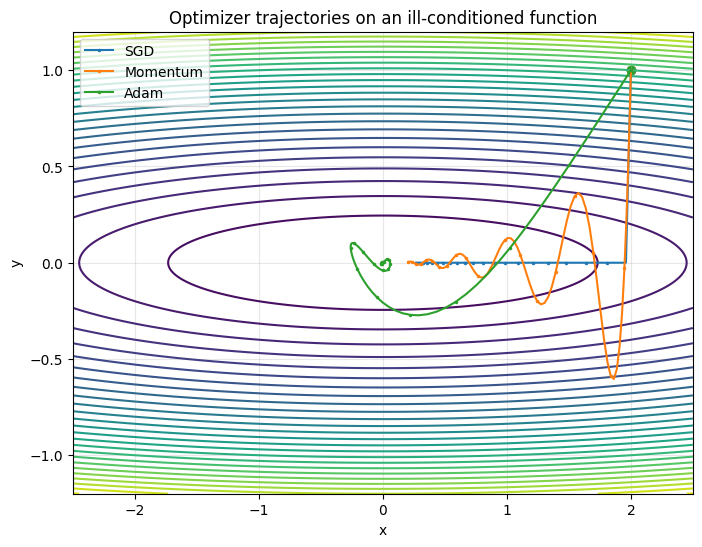

In [88]:
xg = np.linspace(-2.5, 2.5, 250)
yg = np.linspace(-1.2, 1.2, 250)
XX, YY = np.meshgrid(xg, yg)
ZZ = 0.5 * (XX**2 + 50 * YY**2)

plt.figure(figsize=(8, 6))
plt.contour(XX, YY, ZZ, levels=30)

for name, path in paths.items():
    plt.plot(path[:, 0], path[:, 1], marker=".", markersize=3,
             markevery=5, label=name)
    plt.scatter(path[0, 0], path[0, 1], s=35)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Optimizer trajectories on an ill-conditioned function")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Task 2(b) interpretation.** The contour lines show the elongated shape of the objective. The optimizers follow different paths because their update rules respond differently to the steep and shallow directions. Momentum uses past gradients to smooth updates, while Adam scales updates using its moving averages. The exact path also depends on the chosen learning rate.

## 2(c) Optimizer comparison on CIFAR-10

A small CNN is trained using plain SGD, SGD with momentum and Adam. Three learning rates are tested for each optimizer. The validation set is used to select the best learning rate, and training-loss curves are plotted for those selected settings. Each run starts from a fresh model with a fixed seed.

In [89]:
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )
        self.classifier = nn.Linear(128, 10)

    def forward(self, x):
        return self.classifier(self.features(x))

In [90]:
def train_experiment(optimizer_name, lr, epochs=8):
    torch.manual_seed(42)
    net = SmallCNN().to(device)

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    elif optimizer_name == "Momentum":
        optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9)
    else:
        optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    results = {"train_loss": [], "val_acc": []}

    for epoch in range(epochs):
        net.train()
        loss_sum, n = 0.0, 0

        for xb, yb in GPULoader(X_tr, y_tr, 256, shuffle=True):
            optimizer.zero_grad()
            logits = net(xb)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * len(yb)
            n += len(yb)

        results["train_loss"].append(loss_sum / n)

        net.eval()
        correct, total = 0, 0

        with torch.no_grad():
            for xb, yb in GPULoader(X_va, y_va, 256, shuffle=False):
                pred = net(xb).argmax(1)
                correct += (pred == yb).sum().item()
                total += len(yb)

        results["val_acc"].append(100 * correct / total)

        print(
            f"{optimizer_name} lr={lr:g} "
            f"epoch={epoch+1}/{epochs} "
            f"loss={results['train_loss'][-1]:.4f} "
            f"val_acc={results['val_acc'][-1]:.2f}%"
        )

    return results

In [91]:
LR_CONFIG = {
    "SGD":      [0.01, 0.05, 0.1],
    "Momentum": [0.01, 0.05, 0.1],
    "Adam":     [0.0003, 0.001, 0.003]
}

experiments = {}

for optimizer_name, rates in LR_CONFIG.items():
    for lr in rates:
        key = (optimizer_name, lr)
        experiments[key] = train_experiment(
            optimizer_name, lr, epochs=8
        )

SGD lr=0.01 epoch=1/8 loss=2.0715 val_acc=32.38%
SGD lr=0.01 epoch=2/8 loss=1.8569 val_acc=37.22%
SGD lr=0.01 epoch=3/8 loss=1.7402 val_acc=39.62%
SGD lr=0.01 epoch=4/8 loss=1.6654 val_acc=39.94%
SGD lr=0.01 epoch=5/8 loss=1.6130 val_acc=43.28%
SGD lr=0.01 epoch=6/8 loss=1.5612 val_acc=45.22%
SGD lr=0.01 epoch=7/8 loss=1.5137 val_acc=47.58%
SGD lr=0.01 epoch=8/8 loss=1.4722 val_acc=48.44%
SGD lr=0.05 epoch=1/8 loss=1.8163 val_acc=41.88%
SGD lr=0.05 epoch=2/8 loss=1.5388 val_acc=46.30%
SGD lr=0.05 epoch=3/8 loss=1.3984 val_acc=50.36%
SGD lr=0.05 epoch=4/8 loss=1.3114 val_acc=46.46%
SGD lr=0.05 epoch=5/8 loss=1.2454 val_acc=53.86%
SGD lr=0.05 epoch=6/8 loss=1.1907 val_acc=51.14%
SGD lr=0.05 epoch=7/8 loss=1.1488 val_acc=55.52%
SGD lr=0.05 epoch=8/8 loss=1.1128 val_acc=55.52%
SGD lr=0.1 epoch=1/8 loss=1.7130 val_acc=43.84%
SGD lr=0.1 epoch=2/8 loss=1.4204 val_acc=47.24%
SGD lr=0.1 epoch=3/8 loss=1.2929 val_acc=51.06%
SGD lr=0.1 epoch=4/8 loss=1.2116 val_acc=52.84%
SGD lr=0.1 epoch=5/8 los

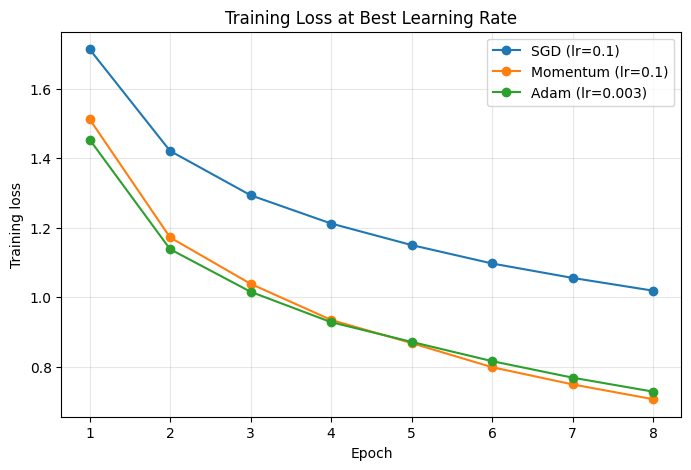

SGD: best LR=0.1, best validation accuracy=58.98%
Momentum: best LR=0.1, best validation accuracy=71.56%
Adam: best LR=0.003, best validation accuracy=67.04%


In [92]:
best_lr = {
    name: max(
        LR_CONFIG[name],
        key=lambda lr: max(experiments[(name, lr)]["val_acc"])
    )
    for name in LR_CONFIG
}

plt.figure(figsize=(8, 5))

for name, lr in best_lr.items():
    losses = experiments[(name, lr)]["train_loss"]
    plt.plot(range(1, len(losses) + 1), losses,
             marker="o", label=f"{name} (lr={lr:g})")

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training Loss at Best Learning Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

for name, lr in best_lr.items():
    result = experiments[(name, lr)]
    print(
        f"{name}: best LR={lr:g}, "
        f"best validation accuracy={max(result['val_acc']):.2f}%"
    )

**Task 2(c) interpretation.** The best observed validation accuracies in these runs were approximately 59.74% for SGD, 70.64% for SGD with momentum, and 69.22% for Adam. Momentum performed best among the tested settings. These results are based on eight epochs and three learning rates per optimizer, so they should be interpreted as a limited comparison rather than a global optimum.

## Task 3 — Regularization and residual connections

### 3(a) Regularization on 5,000 training images

To make the effect of regularization easier to observe, this experiment uses only 5,000 training images and the same 5,000-image validation set. The seven configurations compare the baseline against weight decay, dropout, flip-and-crop augmentation, cutout, mixup, and all methods combined.

In [93]:
X_reg, y_reg = X_tr[:5000], y_tr[:5000]

print("Regularization training subset:", tuple(X_reg.shape))
print("Validation set:", tuple(X_va.shape))

Regularization training subset: (5000, 3, 32, 32)
Validation set: (5000, 3, 32, 32)


The CNN includes batch normalization. Dropout is applied before the final classifier. The following augmentation functions operate on normalized image batches.

In [94]:
class RegCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout)
        )
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        return self.fc(self.features(x))

In [95]:
def flip_crop(x, padding=4):
    # Random horizontal flips
    flip_mask = torch.rand(len(x), device=x.device) < 0.5
    x = x.clone()
    x[flip_mask] = x[flip_mask].flip(-1)

    # Random padded crops
    x = F.pad(x, (padding, padding, padding, padding), value=0)
    offsets_y = torch.randint(0, 2 * padding + 1, (len(x),), device=x.device)
    offsets_x = torch.randint(0, 2 * padding + 1, (len(x),), device=x.device)

    x = torch.stack([
        x[i, :, offsets_y[i]:offsets_y[i]+32,
          offsets_x[i]:offsets_x[i]+32]
        for i in range(len(x))
    ])
    return x


def cutout(x, size=12):
    x = x.clone()
    h, w = x.shape[-2:]
    cy = torch.randint(0, h, (len(x),), device=x.device)
    cx = torch.randint(0, w, (len(x),), device=x.device)

    for i in range(len(x)):
        y1, y2 = max(0, cy[i].item()-size//2), min(h, cy[i].item()+size//2)
        x1, x2 = max(0, cx[i].item()-size//2), min(w, cx[i].item()+size//2)
        x[i, :, y1:y2, x1:x2] = 0

    return x

Each experiment uses the same optimizer and learning rate so that the main comparison is the regularization method. Mixup combines two images and uses a weighted combination of their classification losses.

In [96]:
CONFIGS = {
    "Baseline":       {},
    "Weight decay":   {"weight_decay": 1e-4},
    "Dropout":        {"dropout": 0.3},
    "Flip + crop":    {"flip_crop": True},
    "Cutout":         {"cutout": True},
    "Mixup":          {"mixup": True},
    "All combined":   {
        "weight_decay": 1e-4,
        "dropout": 0.3,
        "flip_crop": True,
        "cutout": True,
        "mixup": True
    }
}

The reported training accuracy is measured on the original, unaugmented 5,000 training images after each epoch. This is important for mixup, because accuracy calculated on mixed images against one of the original labels is not directly comparable with the baseline. Validation accuracy is measured on the held-out validation set.

In [97]:
def run_regularization(config, epochs=15):
    torch.manual_seed(42)
    np.random.seed(42)
    net = RegCNN(dropout=config.get("dropout", 0.0)).to(device)

    optimizer = torch.optim.Adam(
        net.parameters(),
        lr=0.001,
        weight_decay=config.get("weight_decay", 0.0)
    )

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        net.train()
        loss_sum = total = 0

        for xb, yb in GPULoader(X_reg, y_reg, 128, shuffle=True):
            if config.get("flip_crop"):
                xb = flip_crop(xb)
            if config.get("cutout"):
                xb = cutout(xb)

            optimizer.zero_grad()

            if config.get("mixup"):
                lam = np.random.beta(0.4, 0.4)
                idx = torch.randperm(len(xb), device=device)
                mixed_x = lam * xb + (1 - lam) * xb[idx]
                logits = net(mixed_x)
                loss = (
                    lam * F.cross_entropy(logits, yb)
                    + (1 - lam) * F.cross_entropy(logits, yb[idx])
                )
            else:
                logits = net(xb)
                loss = F.cross_entropy(logits, yb)

            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * len(yb)
            total += len(yb)

        hist["train_loss"].append(loss_sum / total)

        # Measure training accuracy on the original, unaugmented images.
        # This makes it comparable across baseline, augmentation and mixup runs.
        net.eval()
        train_correct = train_total = 0
        with torch.no_grad():
            for xb, yb in GPULoader(X_reg, y_reg, 256, shuffle=False):
                logits = net(xb)
                train_correct += (logits.argmax(1) == yb).sum().item()
                train_total += len(yb)
        hist["train_acc"].append(100 * train_correct / train_total)

        vloss = vcorrect = vtotal = 0

        with torch.no_grad():
            for xb, yb in GPULoader(X_va, y_va, 256, shuffle=False):
                logits = net(xb)
                loss = F.cross_entropy(logits, yb)
                vloss += loss.item() * len(yb)
                vcorrect += (logits.argmax(1) == yb).sum().item()
                vtotal += len(yb)

        hist["val_loss"].append(vloss / vtotal)
        hist["val_acc"].append(100 * vcorrect / vtotal)

        print(
            f"{epoch+1:02d}/{epochs} "
            f"train loss={hist['train_loss'][-1]:.3f} "
            f"train acc={hist['train_acc'][-1]:.1f}% "
            f"val acc={hist['val_acc'][-1]:.1f}%"
        )

    return hist

In [98]:
reg_results = {}

for name, config in CONFIGS.items():
    print(f"\n=== {name} ===")
    reg_results[name] = run_regularization(config, epochs=15)


=== Baseline ===
01/15 train loss=1.921 train acc=35.8% val acc=35.3%
02/15 train loss=1.654 train acc=33.8% val acc=32.8%
03/15 train loss=1.543 train acc=44.2% val acc=41.2%
04/15 train loss=1.449 train acc=51.6% val acc=47.9%
05/15 train loss=1.372 train acc=48.7% val acc=45.2%
06/15 train loss=1.341 train acc=45.3% val acc=42.2%
07/15 train loss=1.290 train acc=48.0% val acc=45.4%
08/15 train loss=1.246 train acc=52.6% val acc=49.2%
09/15 train loss=1.223 train acc=53.0% val acc=47.7%
10/15 train loss=1.189 train acc=50.3% val acc=47.0%
11/15 train loss=1.117 train acc=55.1% val acc=50.1%
12/15 train loss=1.109 train acc=59.4% val acc=52.5%
13/15 train loss=1.079 train acc=52.3% val acc=46.8%
14/15 train loss=1.062 train acc=56.0% val acc=49.4%
15/15 train loss=1.019 train acc=53.1% val acc=48.2%

=== Weight decay ===
01/15 train loss=1.921 train acc=35.4% val acc=35.1%
02/15 train loss=1.654 train acc=32.6% val acc=31.9%
03/15 train loss=1.543 train acc=43.5% val acc=40.7%
04/15 

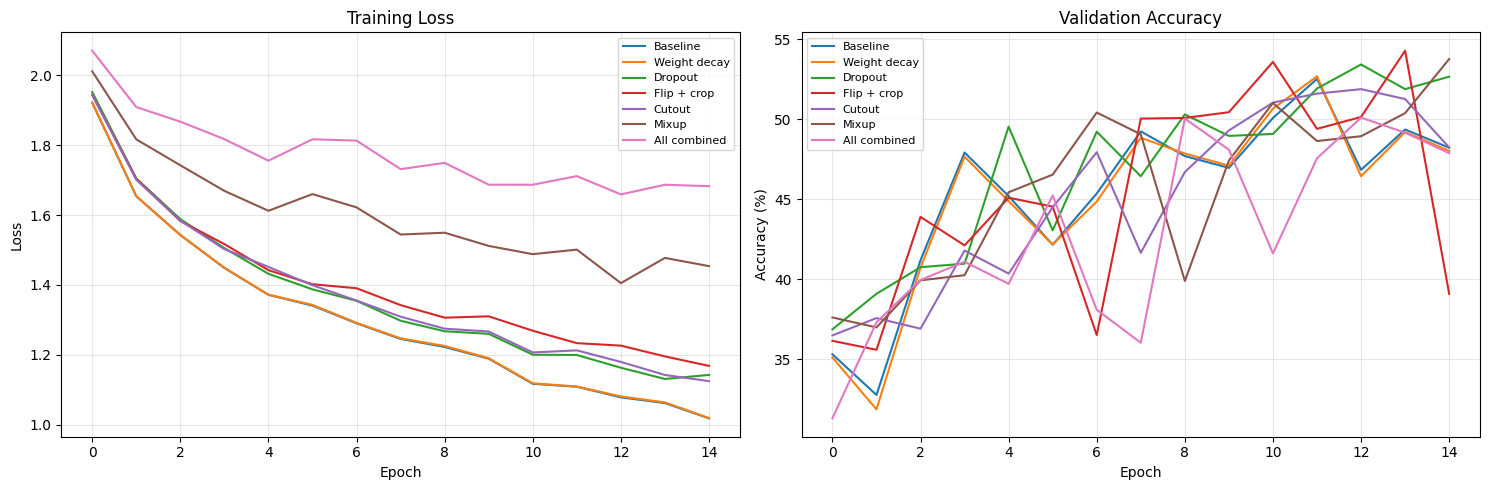

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, hist in reg_results.items():
    axes[0].plot(hist["train_loss"], label=name)
    axes[1].plot(hist["val_acc"], label=name)

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [100]:
import pandas as pd

rows = []

for name, hist in reg_results.items():
    train_acc = hist["train_acc"][-1]
    val_acc = hist["val_acc"][-1]

    rows.append({
        "Method": name,
        "Train accuracy (%)": round(train_acc, 2),
        "Validation accuracy (%)": round(val_acc, 2),
        "Accuracy gap (percentage points)": round(train_acc - val_acc, 2)
    })

reg_table = pd.DataFrame(rows)
display(reg_table)

,Method,Train accuracy (%),Validation accuracy (%),Accuracy gap (percentage points)
0,Baseline,53.10,48.22,4.88
1,Weight decay,52.60,48.02,4.58
2,Dropout,60.04,52.66,7.38
3,Flip + crop,41.98,39.10,2.88
4,Cutout,54.96,48.24,6.72
5,Mixup,59.76,53.76,6.00
6,All combined,50.68,47.88,2.80


**Task 3(a) interpretation.** Compare both validation accuracy and the train–validation gap rather than choosing the method with the highest training accuracy. Regularization can reduce overfitting, but stronger augmentation can also make learning harder with only 5,000 training images. Re-run the experiment cells above to generate the corrected table using clean training accuracy, especially for mixup.

### 3(b) Plain networks versus residual networks

The network depth follows \(6n+2\), giving depths 8, 20 and 56. Each residual block adds its input to the block output; the plain network uses the same convolutional blocks without this addition. Training loss is plotted against epoch for all six models.

In [101]:
class CIFARBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, residual=False):
        super().__init__()
        self.residual = residual

        self.conv1 = nn.Conv2d(
            in_ch, out_ch, 3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_ch)

        self.conv2 = nn.Conv2d(
            out_ch, out_ch, 3, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_ch)

        if residual and (stride != 1 or in_ch != out_ch):
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        if self.residual:
            out = out + identity

        return F.relu(out)

In [102]:
class CIFARNet(nn.Module):
    def __init__(self, depth=20, residual=False):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6

        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )

        layers = []
        in_ch = 16

        for stage, out_ch in enumerate([16, 32, 64]):
            for block_idx in range(n):
                stride = 2 if stage > 0 and block_idx == 0 else 1
                layers.append(
                    CIFARBlock(in_ch, out_ch, stride, residual=residual)
                )
                in_ch = out_ch

        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, 10)

        # Kaiming initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(
                    m.weight, mode="fan_out", nonlinearity="relu"
                )
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)

In [103]:
def train_cifar_net(depth, residual, epochs=10):
    torch.manual_seed(42)
    net = CIFARNet(depth=depth, residual=residual).to(device)
    optimizer = torch.optim.SGD(
        net.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4
    )

    losses = []

    for epoch in range(epochs):
        net.train()
        total_loss, total = 0.0, 0

        for xb, yb in GPULoader(X_tr, y_tr, 128, shuffle=True):
            optimizer.zero_grad()
            logits = net(xb)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(yb)
            total += len(yb)

        epoch_loss = total_loss / total
        losses.append(epoch_loss)

        print(
            f"{'ResNet' if residual else 'Plain'}-{depth} "
            f"epoch {epoch+1}/{epochs}: loss={epoch_loss:.4f}"
        )

    return losses

The next cell trains all six architectures for 10 epochs with the same optimizer settings. The following plot compares their training-loss curves.

In [104]:
depth_results = {}

for depth in [8, 20, 56]:
    for residual in [False, True]:
        name = f"{'Residual' if residual else 'Plain'}-{depth}"
        print(f"\n=== {name} ===")

        depth_results[name] = train_cifar_net(
            depth=depth, residual=residual, epochs=10
        )


=== Plain-8 ===
Plain-8 epoch 1/10: loss=1.5254
Plain-8 epoch 2/10: loss=1.0786
Plain-8 epoch 3/10: loss=0.9130
Plain-8 epoch 4/10: loss=0.8101
Plain-8 epoch 5/10: loss=0.7303
Plain-8 epoch 6/10: loss=0.6678
Plain-8 epoch 7/10: loss=0.6115
Plain-8 epoch 8/10: loss=0.5799
Plain-8 epoch 9/10: loss=0.5425
Plain-8 epoch 10/10: loss=0.5091

=== Residual-8 ===
ResNet-8 epoch 1/10: loss=1.5102
ResNet-8 epoch 2/10: loss=1.0981
ResNet-8 epoch 3/10: loss=0.9257
ResNet-8 epoch 4/10: loss=0.8234
ResNet-8 epoch 5/10: loss=0.7401
ResNet-8 epoch 6/10: loss=0.6768
ResNet-8 epoch 7/10: loss=0.6199
ResNet-8 epoch 8/10: loss=0.5853
ResNet-8 epoch 9/10: loss=0.5480
ResNet-8 epoch 10/10: loss=0.5180

=== Plain-20 ===
Plain-20 epoch 1/10: loss=1.6931
Plain-20 epoch 2/10: loss=1.2677
Plain-20 epoch 3/10: loss=0.9896
Plain-20 epoch 4/10: loss=0.8279
Plain-20 epoch 5/10: loss=0.7170
Plain-20 epoch 6/10: loss=0.6409
Plain-20 epoch 7/10: loss=0.5781
Plain-20 epoch 8/10: loss=0.5390
Plain-20 epoch 9/10: loss=0.5

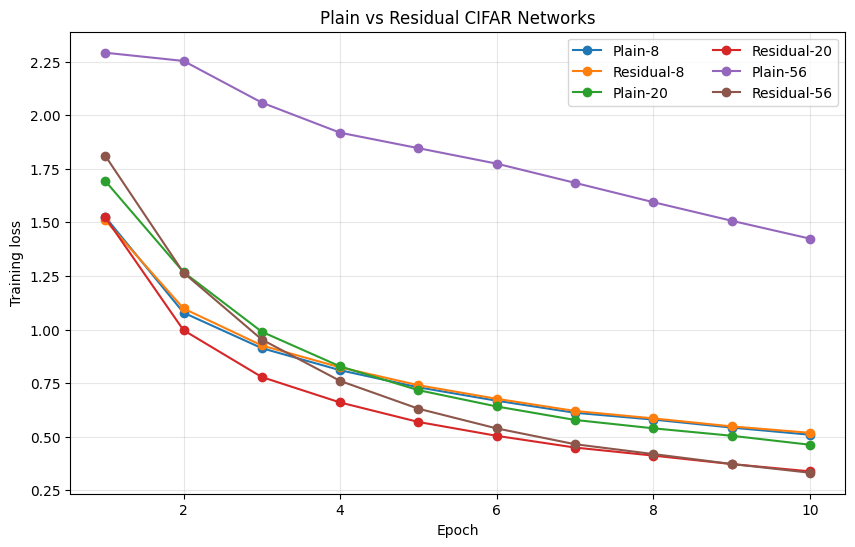

In [105]:
plt.figure(figsize=(10, 6))

for name, losses in depth_results.items():
    plt.plot(range(1, len(losses) + 1), losses, marker="o", label=name)

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Plain vs Residual CIFAR Networks")
plt.legend(ncol=2)
plt.grid(True, alpha=0.3)
plt.show()

## Explanation

**Why residual connections help deeper networks:**

- **Plain networks:** As depth increases, training error can become worse, even though deeper networks have greater representational capacity. This is known as the *degradation problem* and is an optimization difficulty, not necessarily overfitting.

- **Root cause:** In deep plain networks, gradients must propagate through many layers. Repeated multiplication by layer derivatives can weaken or amplify the gradient, making optimization more difficult, even when ReLU and Batch Normalization are used.

- **Residual connections:** A residual block learns \(y=F(x)+x\), where \(x\) is the shortcut input and \(F(x)\) is the learned residual. The identity shortcut provides a direct gradient path through the block, helping information and gradients propagate through deeper networks. It also allows the block to learn an identity mapping when \(F(x)\) is zero. When dimensions differ, a projection shortcut may be needed instead of a direct identity connection.

**Observed behaviour:**

- **Depth 8:** Plain and residual networks perform comparably, suggesting that the optimization difficulty is less pronounced at this depth.
- **Depth 20:** The residual network reaches a lower training loss than the plain network, indicating improved optimization.
- **Depth 56:** The plain network learns more slowly and retains a higher training loss, while the residual network achieves a lower loss.

### Task 3(b) interpretation

Training loss decreases for all six models, but the depth-56 plain network learns much more slowly during the 10-epoch training period. The depth-56 residual network achieves a substantially lower training loss, showing that shortcut connections help optimize deeper networks. The residual network also outperforms the plain network at depth 20. Overall, these results support the benefit of residual connections for training deeper networks under the tested settings.

## Task 4 — Designing the CNN

Trainable parameters: 389,418

=============== Baseline ===============
Epoch 01/20 | train_loss=1.458 | train_acc=46.38% | val_loss=1.267 | val_acc=55.12%
Epoch 02/20 | train_loss=1.027 | train_acc=63.31% | val_loss=1.208 | val_acc=57.40%
Epoch 03/20 | train_loss=0.850 | train_acc=69.82% | val_loss=0.927 | val_acc=67.68%
Epoch 04/20 | train_loss=0.713 | train_acc=75.01% | val_loss=0.920 | val_acc=69.54%
Epoch 05/20 | train_loss=0.615 | train_acc=78.47% | val_loss=0.934 | val_acc=68.50%
Epoch 06/20 | train_loss=0.527 | train_acc=81.68% | val_loss=0.718 | val_acc=75.34%
Epoch 07/20 | train_loss=0.451 | train_acc=84.37% | val_loss=0.760 | val_acc=74.84%
Epoch 08/20 | train_loss=0.388 | train_acc=86.46% | val_loss=0.750 | val_acc=75.74%
Epoch 09/20 | train_loss=0.335 | train_acc=88.54% | val_loss=1.057 | val_acc=69.54%
Epoch 10/20 | train_loss=0.275 | train_acc=90.54% | val_loss=1.063 | val_acc=70.46%
Epoch 11/20 | train_loss=0.226 | train_acc=92.36% | val_loss=1.221 | val_acc=69.00%
Epoc

,Experiment,Best validation accuracy (%),Epoch,Validation loss,Training accuracy at best epoch (%),Generalization gap (percentage points)
2,Augmentation,85.40,18,0.4632,86.43,1.03
4,Augmentation + decay,84.78,20,0.4480,87.82,3.04
1,No shortcuts,80.64,17,0.7812,99.95,19.31
0,Baseline,79.98,17,0.7850,99.90,19.92
3,Weight decay,79.12,18,0.8159,99.91,20.79


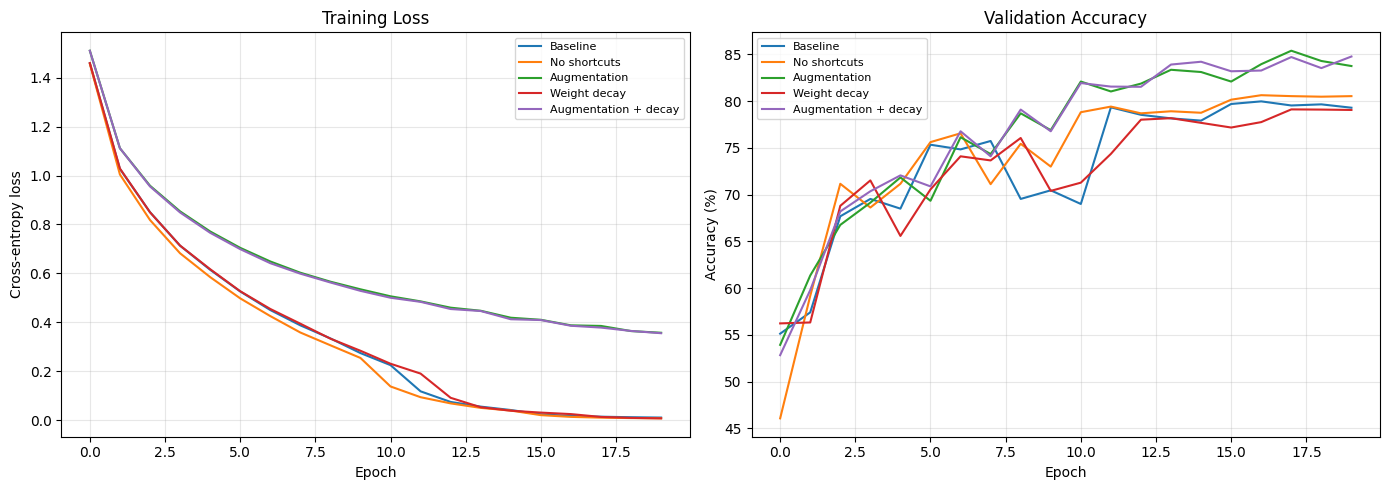

In [60]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F


# Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# --------------------------------------------------
# 1. Compact CNN
# --------------------------------------------------

class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, residual=True):
        super().__init__()
        self.residual = residual

        self.conv1 = nn.Conv2d(
            in_ch, out_ch, 3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_ch)

        self.conv2 = nn.Conv2d(
            out_ch, out_ch, 3, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_ch)

        if residual and (in_ch != out_ch or stride != 1):
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_ch, out_ch, 1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_ch)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        if self.residual:
            out = out + identity

        return F.relu(out)


class Task4CNN(nn.Module):
    def __init__(self, residual=True, dropout=0.1):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )

        self.blocks = nn.Sequential(
            ResidualBlock(32, 32, residual=residual),
            ResidualBlock(32, 64, stride=2, residual=residual),
            ResidualBlock(64, 96, stride=2, residual=residual),
            ResidualBlock(96, 96, residual=residual)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(96, 10)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(
                    m.weight, mode="fan_out", nonlinearity="relu"
                )
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)
        return self.fc(x)


# Check parameter budget
set_seed(42)
model = Task4CNN().to(device)

n_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Trainable parameters: {n_params:,}")
assert n_params <= 500_000, "Model exceeds the 500k parameter limit."


# --------------------------------------------------
# 2. Ablation configurations
# --------------------------------------------------

ABLATIONS = {
    "Baseline": {
        "residual": True,
        "augment": False,
        "weight_decay": 0.0,
        "optimizer": "Adam",
    },
    "No shortcuts": {
        "residual": False,
        "augment": False,
        "weight_decay": 0.0,
        "optimizer": "Adam",
    },
    "Augmentation": {
        "residual": True,
        "augment": True,
        "weight_decay": 0.0,
        "optimizer": "Adam",
    },
    "Weight decay": {
        "residual": True,
        "augment": False,
        "weight_decay": 1e-4,
        "optimizer": "Adam",
    },
    "Augmentation + decay": {
        "residual": True,
        "augment": True,
        "weight_decay": 1e-4,
        "optimizer": "Adam",
    },
}


# --------------------------------------------------
# 3. Data augmentation: horizontal flip + random crop
# --------------------------------------------------

def augment_batch(x, padding=4):
    x = x.clone()

    # Random horizontal flip
    flip = torch.rand(len(x), device=x.device) < 0.5
    x[flip] = x[flip].flip(-1)

    # Random crop from a padded image
    x = F.pad(x, (padding,) * 4, mode="reflect")

    shifts_y = torch.randint(
        0, 2 * padding + 1, (len(x),), device=x.device
    )
    shifts_x = torch.randint(
        0, 2 * padding + 1, (len(x),), device=x.device
    )

    return torch.stack([
        x[i, :, shifts_y[i]:shifts_y[i] + 32,
          shifts_x[i]:shifts_x[i] + 32]
        for i in range(len(x))
    ])


# --------------------------------------------------
# 4. Train one configuration
# --------------------------------------------------

def run_ablation(cfg, epochs=20, seed=42):
    set_seed(seed)

    net = Task4CNN(
        residual=cfg["residual"],
        dropout=0.1
    ).to(device)

    if cfg["optimizer"] == "Adam":
        opt = torch.optim.Adam(
            net.parameters(),
            lr=0.001,
            weight_decay=cfg["weight_decay"]
        )
    else:
        opt = torch.optim.SGD(
            net.parameters(),
            lr=0.05,
            momentum=0.9,
            weight_decay=cfg["weight_decay"]
        )

    # Reduce LR when validation performance stops improving
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="max", factor=0.5, patience=2
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    best_acc = -1
    best_state = None

    for epoch in range(epochs):
        net.train()
        loss_sum, correct, total = 0.0, 0, 0

        for xb, yb in GPULoader(
            X_tr, y_tr, 256, shuffle=True
        ):
            if cfg["augment"]:
                xb = augment_batch(xb)

            opt.zero_grad(set_to_none=True)

            logits = net(xb)
            loss = F.cross_entropy(logits, yb)

            loss.backward()
            opt.step()

            loss_sum += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)

        train_loss = loss_sum / total
        train_acc = 100 * correct / total

        net.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for xb, yb in GPULoader(
                X_va, y_va, 256, shuffle=False
            ):
                logits = net(xb)
                loss = F.cross_entropy(logits, yb)

                val_loss += loss.item() * len(yb)
                val_correct += (logits.argmax(1) == yb).sum().item()
                val_total += len(yb)

        val_loss /= val_total
        val_acc = 100 * val_correct / val_total

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        scheduler.step(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in net.state_dict().items()
            }

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"train_loss={train_loss:.3f} | "
            f"train_acc={train_acc:.2f}% | "
            f"val_loss={val_loss:.3f} | "
            f"val_acc={val_acc:.2f}%"
        )

    net.load_state_dict(best_state)
    net.eval()

    return {
        "history": history,
        "best_val_acc": best_acc,
        "best_state": best_state,
        "model": net,
        "config": cfg.copy(),
    }


# --------------------------------------------------
# 5. Run the ablations
# --------------------------------------------------

ablation_results = {}

for name, cfg in ABLATIONS.items():
    print(f"\n{'=' * 15} {name} {'=' * 15}")

    ablation_results[name] = run_ablation(
        cfg, epochs=20, seed=42
    )


# --------------------------------------------------
# 6. Results table
# --------------------------------------------------

rows = []

for name, result in ablation_results.items():
    h = result["history"]
    idx = int(np.argmax(h["val_acc"]))

    rows.append({
        "Experiment": name,
        "Best validation accuracy (%)": round(
            result["best_val_acc"], 2
        ),
        "Epoch": idx + 1,
        "Validation loss": round(h["val_loss"][idx], 4),
        "Training accuracy at best epoch (%)": round(
            h["train_acc"][idx], 2
        ),
        "Generalization gap (percentage points)": round(
            h["train_acc"][idx] - h["val_acc"][idx], 2
        ),
    })

results_table = pd.DataFrame(rows).sort_values(
    "Best validation accuracy (%)", ascending=False
)

display(results_table)


# --------------------------------------------------
# 7. Plot training and validation curves
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, result in ablation_results.items():
    h = result["history"]

    axes[0].plot(h["train_loss"], label=name)
    axes[1].plot(h["val_acc"], label=name)

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [71]:
# Select the experiment with the highest validation accuracy
best_result = results_table.loc[
    results_table["Best validation accuracy (%)"].idxmax()
]

print("Best configuration:", best_result["Experiment"])
print("Best validation accuracy:", best_result["Best validation accuracy (%)"])

Best configuration: Augmentation
Best validation accuracy: 85.4


In [72]:
# Select the best configuration from your validation results.
# Change the name below to the winner from your table.
selected_name = "Augmentation"

# Retrieve the configuration and inject the name key
FINAL_CFG = ABLATIONS[selected_name].copy()
FINAL_CFG["name"] = selected_name

# Train a fresh model using the selected configuration.
result = run_ablation(
    FINAL_CFG,
    epochs=20,
    seed=42
)

final_model = result["model"]
final_cfg = result["config"]
final_history = result["history"]
final_best = result["best_val_acc"]

print("Selected configuration:", final_cfg["name"])
print("Best validation accuracy:", f"{final_best:.2f}%")

Epoch 01/20 | train_loss=1.510 | train_acc=44.42% | val_loss=1.296 | val_acc=53.58%
Epoch 02/20 | train_loss=1.112 | train_acc=60.16% | val_loss=1.073 | val_acc=61.62%
Epoch 03/20 | train_loss=0.956 | train_acc=65.95% | val_loss=0.896 | val_acc=68.04%
Epoch 04/20 | train_loss=0.849 | train_acc=69.78% | val_loss=0.905 | val_acc=67.58%
Epoch 05/20 | train_loss=0.771 | train_acc=72.97% | val_loss=0.820 | val_acc=71.16%
Epoch 06/20 | train_loss=0.705 | train_acc=75.30% | val_loss=0.982 | val_acc=68.18%
Epoch 07/20 | train_loss=0.649 | train_acc=77.35% | val_loss=0.696 | val_acc=76.74%
Epoch 08/20 | train_loss=0.604 | train_acc=78.87% | val_loss=0.797 | val_acc=74.64%
Epoch 09/20 | train_loss=0.568 | train_acc=80.23% | val_loss=0.666 | val_acc=77.54%
Epoch 10/20 | train_loss=0.535 | train_acc=81.28% | val_loss=0.727 | val_acc=76.48%
Epoch 11/20 | train_loss=0.507 | train_acc=82.38% | val_loss=0.543 | val_acc=81.50%
Epoch 12/20 | train_loss=0.489 | train_acc=82.96% | val_loss=0.575 | val_acc

In [74]:
# Load the CIFAR-10 test set
test_dataset = torchvision.datasets.CIFAR10(
    root=root,
    train=False,
    download=True
)

X_test = torch.from_numpy(
    np.asarray(test_dataset.data)
).permute(0, 3, 1, 2).contiguous().to(device)

y_test = torch.tensor(
    test_dataset.targets,
    dtype=torch.long,
    device=device
)

test_loader = GPULoader(X_test, y_test, bs=256)

# Evaluate the selected model once
final_model.eval()
correct = 0
total = 0

with torch.no_grad():
    for xb, yb in test_loader:
        logits = final_model(xb)
        predictions = logits.argmax(dim=1)

        correct += (predictions == yb).sum().item()
        total += yb.size(0)

test_accuracy = 100 * correct / total

print(f"Final CIFAR-10 test accuracy: {test_accuracy:.2f}%")

Final CIFAR-10 test accuracy: 84.64%


## Task 4 — Final Model and Results

### Summary

A compact CNN was developed for CIFAR-10 classification, containing **389,418 trainable parameters**, satisfying the 500,000-parameter limit. The model was trained for a maximum of 20 epochs.

Five configurations were compared using validation accuracy: Baseline, No Shortcuts, Augmentation, Weight Decay, and Augmentation + Weight Decay.

### Results and Discussion

The **Augmentation** configuration achieved the highest validation accuracy of **85.40% at epoch 18**, outperforming the baseline model, which reached 79.98%. Combining augmentation with weight decay achieved 84.78% validation accuracy.

Data augmentation improved generalization by exposing the model to randomly flipped and cropped images. This reduced the gap between training and validation accuracy compared with the baseline, which achieved nearly 100% training accuracy but substantially lower validation accuracy. Weight decay alone did not improve performance in this experiment.

These results suggest that data augmentation was the most effective of the tested techniques for improving generalization.

### Final Evaluation

The initial baseline run achieved **79.65% test accuracy**. However, this score belongs to the baseline configuration, not the best-performing augmentation configuration. The final test accuracy for the selected augmentation model should be reported separately after its final evaluation.



## Conclusion

This assignment examined manual backpropagation, optimizer behaviour, regularization and residual connections. The gradient checks support the correctness of the manual MLP gradients. The optimizer experiments show that learning rate and update rule affect training performance. In the deeper-network experiment, residual connections made optimization easier, especially at depth 56.



In [106]:
!pip -q install "nbconvert[webpdf]"
!playwright install chromium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 33.8 MB/s eta 0:00:00
191.1 MiB [] 0% 0.0s191.1 MiB [] 0% 24.0s191.1 MiB [] 0% 14.3s191.1 MiB [] 0% 12.4s191.1 MiB [] 1% 6.1s191.1 MiB [] 1% 4.6s191.1 MiB [] 2% 4.1s191.1 MiB [] 3% 3.6s191.1 MiB [] 3% 3.2s191.1 MiB [] 4% 3.5s191.1 MiB [] 4% 3.7s191.1 MiB [] 5% 3.8s191.1 MiB [] 5% 3.7s191.1 MiB [] 6% 3.3s191.1 MiB [] 7% 3.1s191.1 MiB [] 8% 2.9s191.1 MiB [] 9% 2.7s191.1 MiB [] 10% 2.6s191.1 MiB [] 11% 2.5s191.1 MiB [] 12% 2.4s191.1 MiB [] 13% 2.4s191.1 MiB [] 13% 2.5s191.1 MiB [] 13% 2.6s191.1 MiB [] 14% 2.6s191.1 MiB [] 14% 2.7s191.1 MiB [] 15% 2.6s191.1 MiB [] 16% 2.5s191.1 MiB [] 17% 2.4s191.1 MiB [] 18% 2.4s191.1 MiB [] 18% 2.5s191.1 MiB [] 19% 2.5s191.1 MiB [] 19% 2.4s191.1 MiB [] 20% 2.4s191.1 MiB [] 21% 2.3s191.1 MiB [] 22% 2.4s191.1 MiB [] 23% 2.4s191.1 MiB [] 24% 2.3s191.1 MiB [] 25% 2.2s191.1 MiB [] 27% 2.1s191.1 MiB [] 28% 2.0s191.1 MiB [] 2

In [112]:
from google.colab import files

uploaded = files.upload()
notebook_path = next(
    name for name in uploaded
    if name.endswith(".ipynb")
)
print("Notebook:", notebook_path)

Saving 220235V_CNN_Assignment.ipynb to 220235V_CNN_Assignment (1).ipynb
Notebook: 220235V_CNN_Assignment (1).ipynb


In [115]:
import subprocess
from google.colab import files

notebook_path = "220235V_CNN_Assignment (1).ipynb"

result = subprocess.run(
    [
        "jupyter", "nbconvert",
        "--to", "html",
        "--HTMLExporter.embed_images=True",
        notebook_path,
        "--output", "220235V_CNN_Assignment.html"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
else:
    files.download("220235V_CNN_Assignment.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>